# Chapter 1 · Foundations: the physics model, the sensors, and the twin gap
1D

## What is a digital twin?
A **digital twin** is a computer model of one specific physical object. The model is **kept in
sync with that object through sensor data**. Being in sync lets it do two things the sensors
can't do alone:
* **see between the sensors**: estimate the field everywhere, not just at a few points
* **see ahead**: forecast what will happen next, and what *would* happen if you acted

Every twin here is built from the same five parts:

| Part | Question it answers | Where it is built |
|---|---|---|
| 1. **Physical asset** | what are we twinning? | this chapter (a heated rod) |
| 2. **Physics model** | how does the asset behave? | this chapter, Part A |
| 3. **Sensors** | what can we actually measure? | this chapter, Part B |
| 4. **Synchronisation** | how do data correct the model? | Chapters 2, 3, 5 |
| 5. **Decisions** | what should we do? | Chapter 6 |

This chapter builds parts 1–3. At the end you'll see why they are **not yet a twin**.


In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline
from IPython.display import HTML
from dtwin import viz
from dtwin.solvers import Heat1D
from dtwin.sensors import PointSensors, evenly_spaced_1d
viz.set_style()
np.set_printoptions(precision=3, suppress=True)
rng = np.random.default_rng(42)

---
# Part A · The physics model

## A1. Where the heat equation comes from (energy bookkeeping)
Picture a thin metal rod of length $L$. Cut out one tiny slice between $x$ and $x+\Delta x$ and
do the bookkeeping on its heat:

$$\underbrace{\frac{d}{dt}\big(\rho c\, u\,\Delta x\big)}_{\text{change of heat stored}}
  = \underbrace{q(x)}_{\text{flowing in, left}} - \underbrace{q(x+\Delta x)}_{\text{flowing out, right}}
  + \underbrace{s\,\Delta x}_{\text{heater}}$$

Two facts close the equation:
1. **Fourier's law**: heat flows from hot to cold, in proportion to the slope:
   $q = -k\,\partial u/\partial x$.
2. Divide by $\Delta x$ and let $\Delta x \to 0$: $q(x) - q(x+\Delta x) \to -\partial q/\partial x\;\Delta x$.

Put together, with $\alpha = k/(\rho c)$ and $f = s/(\rho c)$:

$$\boxed{\;\frac{\partial u}{\partial t} = \alpha\,\frac{\partial^2 u}{\partial x^2} + f(x,t)\;}$$

| Symbol | Meaning | Typical value |
|---|---|---|
| $u(x,t)$ | temperature | °C |
| $\alpha$ | thermal diffusivity: how fast heat spreads | copper $1.1\times10^{-4}$, steel $1.2\times10^{-5}$ m²/s |
| $f(x,t)$ | heater, in °C per second | set by the heater power |

**Boundary conditions.** Both ends dip into ice baths, so $u(0,t) = u(L,t) = 0$. Without
boundary and initial conditions the PDE has infinitely many solutions.

**Units, so you don't get scared:** we work in *dimensionless* units with $L = 1$ and
$\alpha \approx 0.01$. Every number in these notebooks is of order one. That keeps the code readable.

## A2. The intuition: curvature drives change
$u_{xx}$ is the **curvature** of the profile.
* At a **hump** (local maximum) $u_{xx} < 0$, so $u_t < 0$: the peak cools.
* In a **valley** $u_{xx} > 0$, so $u_t > 0$: the dip warms.
* On a **straight line** $u_{xx} = 0$: nothing changes, even if the line is tilted.

So heat smooths out bumps:

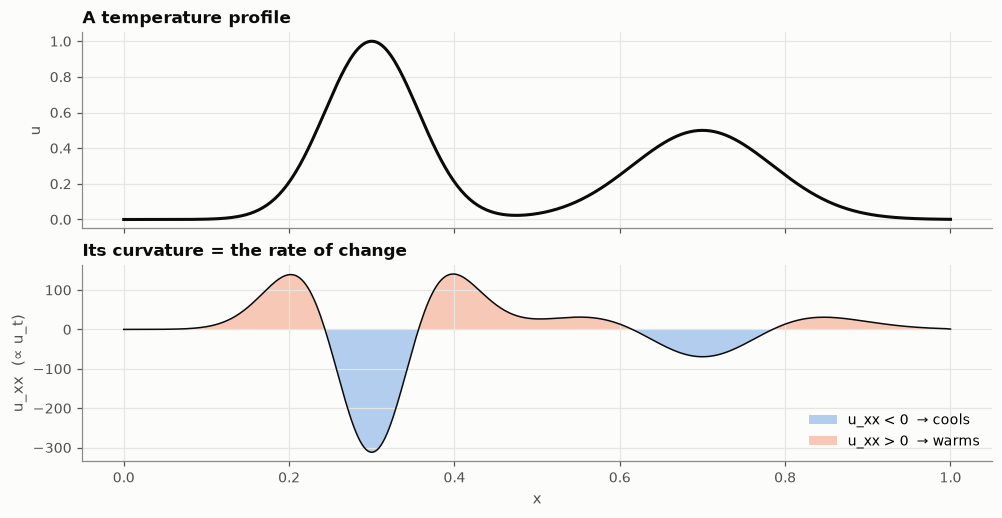

In [2]:
xx = np.linspace(0, 1, 400)
prof = np.exp(-((xx - 0.3) / 0.08) ** 2) + 0.5 * np.exp(-((xx - 0.7) / 0.12) ** 2)
curv = np.gradient(np.gradient(prof, xx), xx)

fig, axes = plt.subplots(2, 1, figsize=(9, 4.6), sharex=True, constrained_layout=True)
axes[0].plot(xx, prof, color=viz.INK)
axes[0].set(ylabel="u", title="A temperature profile")
axes[1].fill_between(xx, curv, 0, where=curv < 0, color=viz.BLUE, alpha=0.35, lw=0,
                     label="u_xx < 0  → cools")
axes[1].fill_between(xx, curv, 0, where=curv > 0, color=viz.ORANGE, alpha=0.35, lw=0,
                     label="u_xx > 0  → warms")
axes[1].plot(xx, curv, color=viz.INK, lw=1)
axes[1].set(xlabel="x", ylabel="u_xx  (∝ u_t)", title="Its curvature = the rate of change")
axes[1].legend(loc="lower right")
plt.show()

The blue regions sit under the peaks and the orange ones on their flanks. The
sharp peak at 0.3 has much stronger curvature than the broad one at 0.7, so it will flatten
faster. Narrow features die fast, broad features live long. Remember this; it explains the
stability limit in A7 and much of Chapter 5.

## A3. From derivatives to arithmetic: finite differences
A computer can't store a continuous function. We keep values only at grid points
$x_i = i\,\Delta x$. How do we get $u_{xx}$ from them? Use a Taylor expansion around $x_i$:

$$u_{i+1} = u_i + \Delta x\,u_x + \tfrac{\Delta x^2}{2}u_{xx} + \tfrac{\Delta x^3}{6}u_{xxx} + \dots$$
$$u_{i-1} = u_i - \Delta x\,u_x + \tfrac{\Delta x^2}{2}u_{xx} - \tfrac{\Delta x^3}{6}u_{xxx} + \dots$$

Add the two lines. The odd terms cancel:

$$\boxed{\;u_{xx} \approx \frac{u_{i+1} - 2u_i + u_{i-1}}{\Delta x^2}\;}\qquad\text{error} \propto \Delta x^2$$

"Error $\propto \Delta x^2$" means **halving the grid spacing cuts the error by four**. Don't
take that on trust; measure it on $u = \sin x$, whose exact curvature is $-\sin x$:

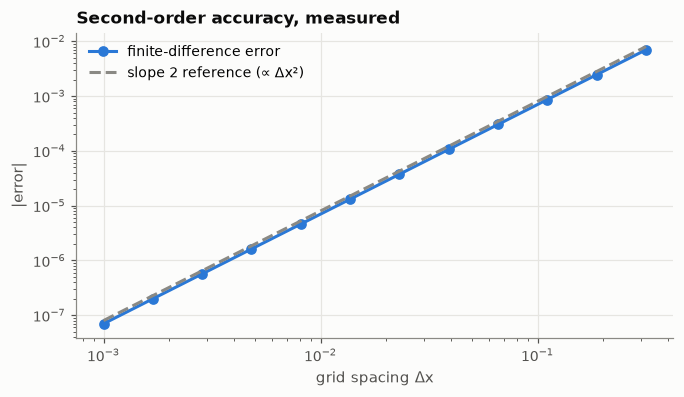

measured slope = 2.00  (theory: 2)


In [3]:
x0 = 1.0
hs = np.logspace(-3, -0.5, 12)
fd = (np.sin(x0 + hs) - 2 * np.sin(x0) + np.sin(x0 - hs)) / hs**2
err_fd = np.abs(fd - (-np.sin(x0)))

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.loglog(hs, err_fd, "o-", color=viz.TWIN, label="finite-difference error")
ax.loglog(hs, 0.08 * hs**2, "--", color=viz.MUTED, label="slope 2 reference (∝ Δx²)")
ax.set(xlabel="grid spacing Δx", ylabel="|error|", title="Second-order accuracy, measured")
ax.legend()
plt.show()
slope = np.polyfit(np.log(hs), np.log(err_fd), 1)[0]
print(f"measured slope = {slope:.2f}  (theory: 2)")

The slope is 2. This little test is called a **convergence study**. It is the
most important habit in scientific computing: *check that your error shrinks at the rate theory
promises.*

## A4. The time step: FTCS, worked by hand
Now step forward in time with $u_t \approx (u_i^{k+1} - u_i^k)/\Delta t$, where the superscript
$k$ counts time steps. Plug both approximations into the PDE and solve for the future value:

$$u_i^{k+1} = u_i^k + r\,\big(u_{i+1}^k - 2u_i^k + u_{i-1}^k\big) + \Delta t\, f_i^k,
  \qquad r = \frac{\alpha\,\Delta t}{\Delta x^2}$$

This is **FTCS**: Forward in Time, Central in Space. The new value at a point depends only on
that point and its two neighbours one step earlier. The single number $r$ controls everything.

Let's do one step by hand on a 5-point rod, with a hot spot in the middle and $r = 0.25$:

In [4]:
u_demo = np.array([0.0, 0.0, 1.0, 0.0, 0.0])
r_demo = 0.25
new = u_demo.copy()
for i in range(1, 4):                          # interior points only; ends stay at 0
    new[i] = u_demo[i] + r_demo * (u_demo[i + 1] - 2 * u_demo[i] + u_demo[i - 1])
    print(f"u_{i}: {u_demo[i]:.2f} + 0.25 * ({u_demo[i+1]:.0f} - 2*{u_demo[i]:.0f} + {u_demo[i-1]:.0f})"
          f" = {new[i]:.2f}")
print("before:", u_demo, "  sum =", u_demo.sum())
print("after: ", new, "  sum =", new.sum())

u_1: 0.00 + 0.25 * (1 - 2*0 + 0) = 0.25
u_2: 1.00 + 0.25 * (0 - 2*1 + 0) = 0.50
u_3: 0.00 + 0.25 * (0 - 2*0 + 1) = 0.25
before: [0. 0. 1. 0. 0.]   sum = 1.0
after:  [0.   0.25 0.5  0.25 0.  ]   sum = 1.0


Read the output: the hot spot gives $2r = 50\%$ of its heat away, a quarter to each
neighbour. Total heat is conserved because nothing has reached the ice-bath ends yet.

With $r = 0.75$ the middle value becomes $1 + 0.75\,(0 - 2 + 0) = -0.5$. The hot spot becomes
**colder than its cold neighbours**. Physics never does that: heat can't overshoot. This is the
seed of the instability in A7.

## A5. The FTCS solver
The loop over $i$ becomes one vectorised NumPy line using slices:
`U[k, 2:]` is "right neighbour", `U[k, :-2]` is "left neighbour".

In [5]:
def ftcs(u0, alpha, dx, dt, n_steps, source=None, x=None):
    """Explicit finite differences for u_t = alpha u_xx + f, ends fixed."""
    U = np.empty((n_steps + 1, u0.size))
    U[0] = u0
    r = alpha * dt / dx**2
    for k in range(n_steps):
        u = U[k].copy()
        u[1:-1] += r * (U[k, 2:] - 2 * U[k, 1:-1] + U[k, :-2])
        if source is not None:
            u[1:-1] += dt * source(x, k * dt)[1:-1]
        U[k + 1] = u
    return U

L, nx, alpha = 1.0, 101, 0.01
x = np.linspace(0, L, nx)
dx = x[1] - x[0]
dt = 0.4 * dx**2 / alpha          # chosen so that r = 0.4
n_steps = int(10.0 / dt)
t = np.arange(n_steps + 1) * dt
print(f"dx = {dx:.3f}, dt = {dt:.4f}, r = {alpha*dt/dx**2:.2f}, steps for 10 time units = {n_steps}")

dx = 0.010, dt = 0.0040, r = 0.40, steps for 10 time units = 2500


## A6. Verification: compare with an exact solution
Start from $u(x,0) = \sin(\pi x)$ with no heater. Plugging $u = a(t)\sin(\pi x)$ into the PDE
gives $a' = -\alpha\pi^2 a$, so the exact answer is

$$u(x,t) = e^{-\alpha\pi^2 t}\,\sin(\pi x).$$

The shape stays the same and only decays. **Always verify a solver before trusting it.** A twin
built on a buggy model can only reproduce the bug, however good its data are.

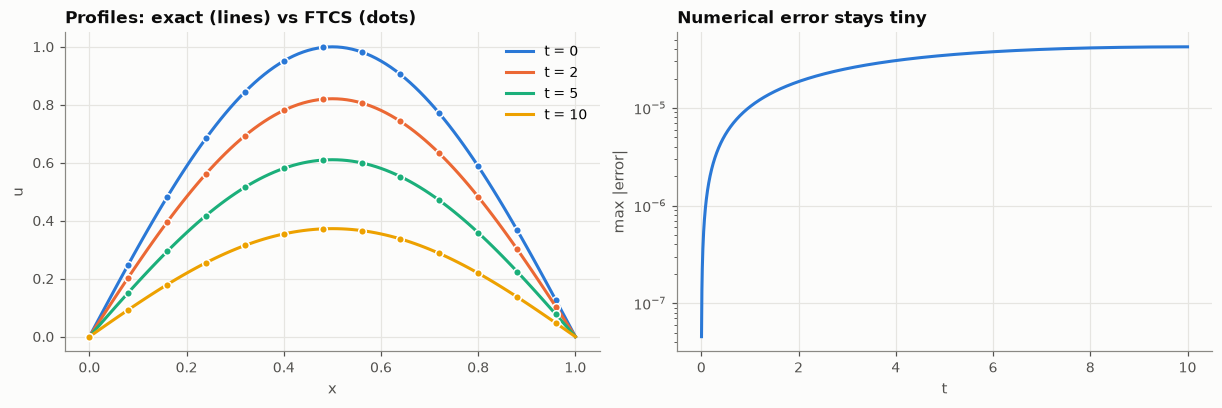

In [6]:
u0 = np.sin(np.pi * x / L)
U_num = ftcs(u0, alpha, dx, dt, n_steps)
U_exact = np.exp(-alpha * np.pi**2 * t[:, None] / L**2) * np.sin(np.pi * x / L)[None]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), constrained_layout=True)
ax = axes[0]
for i, tk in enumerate([0, 2, 5, 10]):
    k = int(round(tk / dt))
    ax.plot(x, U_exact[k], color=viz.SERIES[i], lw=2, label=f"t = {tk}")
    ax.plot(x[::8], U_num[k, ::8], "o", color=viz.SERIES[i], ms=5, mec="white")
ax.set(xlabel="x", ylabel="u", title="Profiles: exact (lines) vs FTCS (dots)")
ax.legend()
axes[1].semilogy(t[1:], np.abs(U_num - U_exact).max(1)[1:], color=viz.TWIN)
axes[1].set(xlabel="t", ylabel="max |error|", title="Numerical error stays tiny")
plt.show()

Now the convergence study for the whole solver. Refine the grid (keeping $r$ fixed) and
measure the error at $t = 2$:

In [7]:
errs, dxs = [], []
for n in [11, 21, 41, 81, 161]:
    xg = np.linspace(0, 1, n); h = xg[1] - xg[0]; dtg = 0.4 * h**2 / alpha
    ng = int(round(2.0 / dtg)); dtg = 2.0 / ng
    Ug = ftcs(np.sin(np.pi * xg), alpha, h, dtg, ng)
    errs.append(np.abs(Ug[-1] - np.exp(-alpha * np.pi**2 * 2) * np.sin(np.pi * xg)).max())
    dxs.append(h)
p = np.polyfit(np.log(dxs), np.log(errs), 1)[0]
for h, e in zip(dxs, errs):
    print(f"dx = {h:.4f}   error = {e:.2e}")
print(f"observed order of accuracy: {p:.2f}")

dx = 0.1000   error = 1.90e-03
dx = 0.0500   error = 4.69e-04
dx = 0.0250   error = 1.17e-04
dx = 0.0125   error = 2.92e-05
dx = 0.0063   error = 7.29e-06
observed order of accuracy: 2.01


Each halving of $\Delta x$ cuts the error by about 4 (order ≈ 2). The solver is
**verified**: it solves the equation we wrote down, to the accuracy we expect.

## A7. Stability: why the time step has a speed limit
Theory says FTCS is stable only if $r = \alpha\Delta t/\Delta x^2 \le \tfrac12$. Let's cross that
line on purpose. We add a little noise to the start, because instability grows from tiny wiggles.

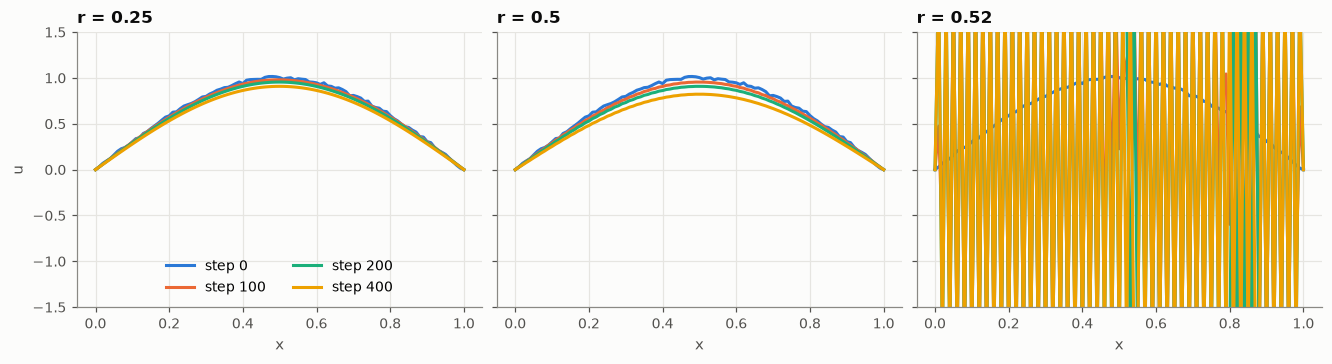

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), constrained_layout=True, sharey=True)
u0_noisy = u0 + 0.01 * np.random.default_rng(0).standard_normal(nx)
u0_noisy[[0, -1]] = 0
for ax, r in zip(axes, [0.25, 0.5, 0.52]):
    dtr = r * dx**2 / alpha
    Ur = ftcs(u0_noisy, alpha, dx, dtr, 400)
    for i, k in enumerate([0, 100, 200, 400]):
        ax.plot(x, np.clip(Ur[k], -2, 2), color=viz.SERIES[i], label=f"step {k}")
    ax.set(title=f"r = {r}", xlabel="x", ylim=(-1.5, 1.5))
axes[0].set_ylabel("u")
axes[0].legend(loc="lower center", ncol=2)
plt.show()

At $r = 0.52$ the result explodes into a saw-tooth. **Why?** Write any profile as a sum of waves
$e^{i\theta j}$, with $\theta = k\Delta x$ running from smooth ($\theta \approx 0$) to the
zig-zag that flips sign at every point ($\theta = \pi$). One FTCS step multiplies each wave by an
**amplification factor**:

$$G(\theta) = 1 - 4r\sin^2(\theta/2).$$

If $|G| > 1$ for any wave, that wave grows every step and eventually swamps everything. The
worst case is the zig-zag, $\theta = \pi$: $G = 1 - 4r$, and $|1 - 4r| \le 1$ requires
$r \le 1/2$. The exact physics multiplies each wave by $e^{-\alpha k^2 \Delta t} \in (0,1)$,
so it always damps.

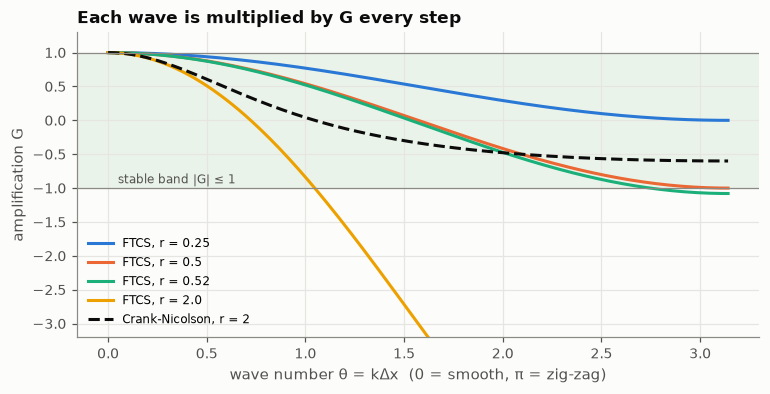

In [9]:
theta = np.linspace(0, np.pi, 200)
fig, ax = plt.subplots(figsize=(8, 3.6))
for i, r in enumerate([0.25, 0.5, 0.52, 2.0]):
    ax.plot(theta, 1 - 4 * r * np.sin(theta / 2) ** 2, color=viz.SERIES[i], label=f"FTCS, r = {r}")
s2 = np.sin(theta / 2) ** 2
ax.plot(theta, (1 - 2 * 2.0 * s2) / (1 + 2 * 2.0 * s2), color=viz.INK, ls="--",
        label="Crank-Nicolson, r = 2")
ax.axhspan(-1, 1, color=viz.GREEN, alpha=0.07, lw=0)
ax.axhline(-1, color=viz.MUTED, lw=0.8); ax.axhline(1, color=viz.MUTED, lw=0.8)
ax.text(0.05, -0.93, "stable band |G| ≤ 1", color=viz.INK2, fontsize=8)
ax.set(xlabel="wave number θ = kΔx  (0 = smooth, π = zig-zag)", ylabel="amplification G",
       ylim=(-3.2, 1.3), title="Each wave is multiplied by G every step")
ax.legend(fontsize=8, loc="lower left")
plt.show()

**The price of stability.** $\Delta t \le \Delta x^2/(2\alpha)$. Halve the grid spacing and you
need **4× more steps**, so 8× more work in total in 1D. In 2D it is 16×. That is a real problem
for a twin that must run faster than real time.

## A8. The fix: an implicit scheme (Crank-Nicolson)
Evaluate the curvature as the **average of now and next step**:

$$\frac{\mathbf u^{k+1} - \mathbf u^k}{\Delta t} = \frac{\alpha}{2}D\,(\mathbf u^{k+1} + \mathbf u^k) + \mathbf f^k
\;\;\Longrightarrow\;\;
\underbrace{\big(I - \tfrac{\alpha\Delta t}{2}D\big)}_{A}\mathbf u^{k+1}
 = \underbrace{\big(I + \tfrac{\alpha\Delta t}{2}D\big)}_{B}\mathbf u^k + \Delta t\,\mathbf f^k$$

Here $D$ is the matrix form of the "$u_{i+1} - 2u_i + u_{i-1}$" stencil. Each step now needs a
linear solve, but $A$ is tridiagonal, so the solve is cheap. Its amplification factor (the dashed
line above) satisfies $|G| \le 1$ for **any** $r$: it is *unconditionally stable*, and
second-order accurate in time as well.

The toolkit class `dtwin.solvers.Heat1D` implements this. Run it with a time step
**50 times** larger than FTCS allows:

In [10]:
dt_big = 50 * 0.5 * dx**2 / alpha
cn = Heat1D(nx=nx, alpha=alpha, dt=dt_big)
t_cn, U_cn = cn.simulate(u0, int(round(10 / dt_big)))
print(f"FTCS limit dt = {0.5*dx**2/alpha:.4f};  CN dt = {dt_big:.3f}  (r = {alpha*dt_big/dx**2:.0f})")
print(f"steps for 10 time units: FTCS {int(10/(0.5*dx**2/alpha))}, CN {len(t_cn)-1}")
print(f"CN max error at t=10: {np.abs(U_cn[-1] - np.exp(-alpha*np.pi**2*10)*u0).max():.1e}")

FTCS limit dt = 0.0050;  CN dt = 0.250  (r = 25)
steps for 10 time units: FTCS 2000, CN 40
CN max error at t=10: 1.2e-05


About 40 steps instead of 2000, and still accurate to about $10^{-5}$. The
matrices also give us something we'll need in Chapter 2: the model in the linear form
$\mathbf u_{k+1} = M\,\mathbf u_k + G\,\mathbf f_k$ (from `Heat1D.transition_matrices()`).
**That linear form is exactly what a Kalman filter needs.**

## A9. Our physical asset: a heated rod
Now the actual asset. Heater A sits at $x=0.3$ and switches on at $t=1$. Heater B sits at
$x=0.75$, is weaker, and runs from $t=4$ to $t=7$. The rod starts cold.


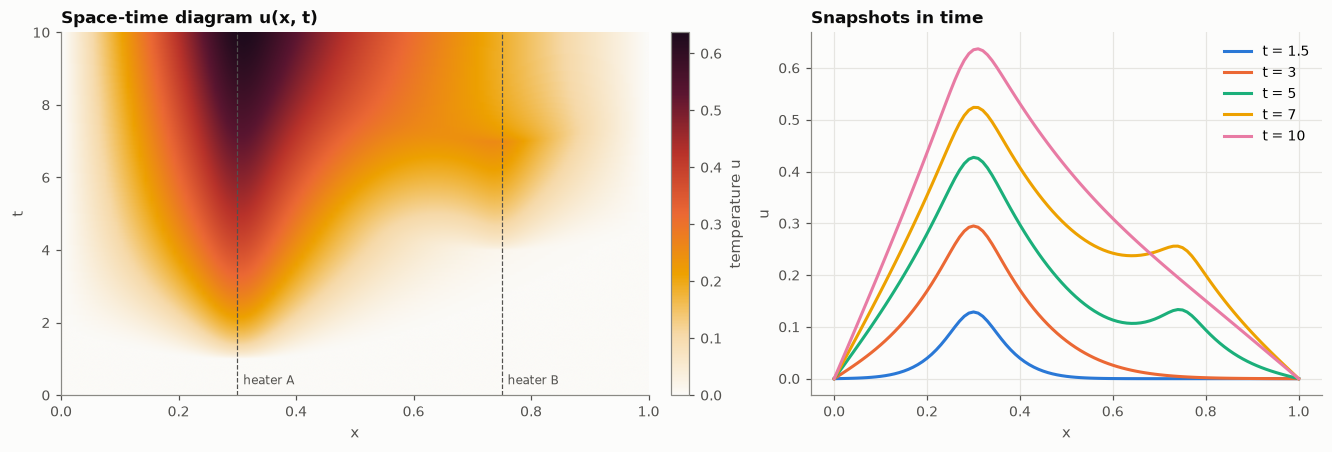

In [11]:
def heaters(x, t):
    f = np.zeros_like(x)
    if t >= 1.0:
        f += 0.6 * np.exp(-((x - 0.3) / 0.04) ** 2)
    if 4.0 <= t < 7.0:
        f += 0.4 * np.exp(-((x - 0.75) / 0.03) ** 2)
    return f

U = ftcs(np.zeros(nx), alpha, dx, dt, n_steps, source=heaters, x=x)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True,
                         gridspec_kw={"width_ratios": [1.15, 1]})
viz.spacetime(axes[0], U, x, t, label="temperature u")
axes[0].set_title("Space-time diagram u(x, t)")
for xs_, lbl in [(0.3, "heater A"), (0.75, "heater B")]:
    axes[0].axvline(xs_, color=viz.INK2, lw=0.8, ls="--")
    axes[0].text(xs_ + 0.01, 0.3, lbl, color=viz.INK2, fontsize=8)
ax = axes[1]
for i, tk in enumerate([1.5, 3, 5, 7, 10]):
    ax.plot(x, U[int(round(tk / dt))], color=viz.SERIES[i], label=f"t = {tk}")
ax.set(xlabel="x", ylabel="u", title="Snapshots in time")
ax.legend()
viz.save(fig, "01_heated_rod.png")
plt.show()

**How to read a space-time diagram.** It is the main picture of these notebooks:
* the **horizontal axis** is position along the rod, the **vertical axis** is time, going up
* a **horizontal slice** is a snapshot of the whole rod at one instant (the right panel)
* a **vertical slice** is the history of one point, which is what a thermometer there would record
* a plume that **widens upward** means heat diffusing outward; **fading** after a heater switches
  off means heat leaking out through the cold ends

## Watching it evolve

In [12]:
idx = np.linspace(0, n_steps, 60).astype(int)
anim = viz.animate_1d(x, [U[idx]], t[idx], labels=["rod temperature"], colors=[viz.ORANGE],
                      title="Heated rod", ylabel="u")
HTML(anim.to_jshtml())

## A10. The energy budget: a physics check that becomes an alarm
Integrate the PDE over the rod. Total heat $E(t) = \int_0^L u\,dx$ obeys

$$\frac{dE}{dt} = \underbrace{\int_0^L f\,dx}_{\text{heater input}} + \underbrace{\alpha\,\big[u_x(L) - u_x(0)\big]}_{\text{flow through the ends}}.$$

If our numbers don't satisfy this, there's a bug. Later the same idea works in reverse: when
**measured** data stop satisfying the budget, something physical has changed (a leak, a fault).
That is the core of physics-based anomaly detection (Chapter 6).

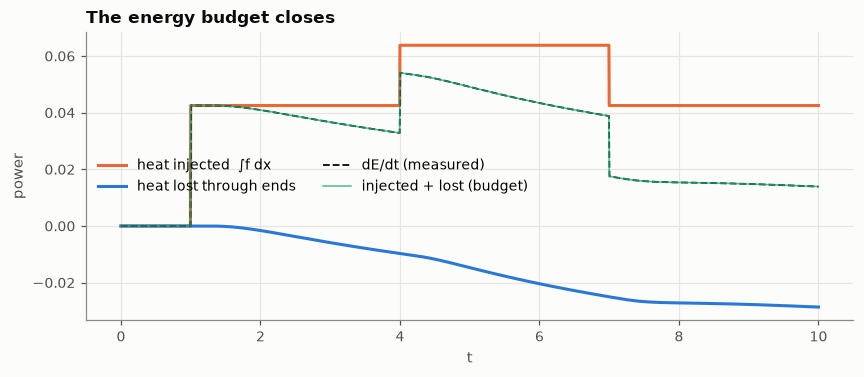

In [13]:
E = np.trapezoid(U, x, axis=1)
inj = np.array([np.trapezoid(heaters(x, tk), x) for tk in t])
leak = alpha * ((U[:, -1] - U[:, -2]) - (U[:, 1] - U[:, 0])) / dx
dEdt = np.gradient(E, dt)

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(t, inj, color=viz.ORANGE, label="heat injected  ∫f dx")
ax.plot(t, leak, color=viz.BLUE, label="heat lost through ends")
ax.plot(t, dEdt, color=viz.INK, lw=1.2, ls="--", label="dE/dt (measured)")
ax.plot(t, inj + leak, color=viz.AQUA, lw=1, alpha=0.8, label="injected + lost (budget)")
ax.set(xlabel="t", ylabel="power", title="The energy budget closes")
ax.legend(ncol=2)
plt.show()

The dashed black line (what actually happened) sits on the aqua line (what the
budget says). The small mismatch at the switch-on instants comes from the finite time step.

**Part A summary.** PDE + grid + time stepper = **simulator**. We verified it three ways: against
an exact solution, with a convergence study, and with a conservation law. And we learnt its
speed limit.

---
# Part B · Sensors: what the twin actually sees

## B1. "Reality" for the rest of this chapter
A real twin never sees the true field. We fake reality with a simulation whose settings we will
**hide from the twin**: diffusivity $\alpha = 0.012$ and a heater whose power changes over time
(an oscillating load, plus a step up at $t = 8$). We use the stable `Heat1D` solver from now on.

In [14]:
TRUE_ALPHA = 0.012

def true_power(t):
    return 0.5 + 0.3 * np.sin(2 * np.pi * t / 6) + 0.4 * (t > 8)

def heater_shape(x):
    return np.exp(-((x - 0.35) / 0.05) ** 2)

real = Heat1D(nx=121, alpha=TRUE_ALPHA, dt=0.02)
x = real.x
t, U_true = real.simulate(np.zeros_like(x), 750, source=lambda x, t: true_power(t) * heater_shape(x))
print(f"state vector size: {real.nx} numbers per instant;  {len(t)} instants")

state vector size: 121 numbers per instant;  751 instants


## B2. The observation operator $H$, step by step
The **state vector** $\mathbf u_k$ holds all 121 temperatures at time $k$. A thermometer at grid
point 30 reads entry 30 of that vector. Stack $m$ thermometers and you get a matrix that is
all zeros except a single 1 in each row:

$$\mathbf y_k = H\,\mathbf u_k + \mathbf v_k, \qquad \mathbf v_k \sim \mathcal N(0, R), \quad R = \sigma^2 I.$$

* $\mathbf y_k$: the $m$ readings, the only thing the twin receives
* $\mathbf v_k$: noise, random with standard deviation $\sigma$
* $R$: the noise covariance. $R = \sigma^2 I$ means every sensor has the same noise and the
  noise of different sensors is independent

A tiny example makes it concrete: an 8-point state with sensors at points 1, 4 and 6.

In [15]:
toy = PointSensors([1, 4, 6], n_state=8, noise_std=0.0)
u_toy = np.array([10, 11, 12, 13, 14, 15, 16, 17.0])
print("H =\n", toy.H.astype(int))
print("H @ u =", toy.H @ u_toy, "  (entries 1, 4, 6 of u)")

H =
 [[0 1 0 0 0 0 0 0]
 [0 0 0 0 1 0 0 0]
 [0 0 0 0 0 0 1 0]]
H @ u = [11. 14. 16.]   (entries 1, 4, 6 of u)


Why bother writing a selection as a matrix? Because every method later on (least squares,
Kalman filters, ensembles) is written with $H$. Swap in a different $H$ and the same code handles
averaging sensors, satellite pixels or line integrals.

Now six real thermocouples, each with noise $\sigma = 0.01$:

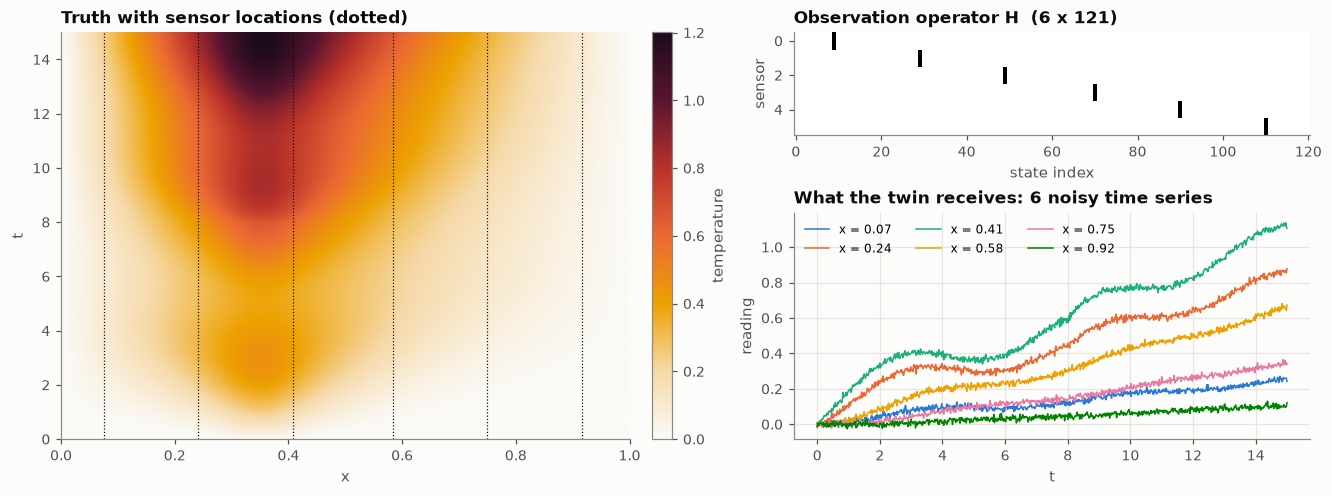

In [16]:
sens = PointSensors(evenly_spaced_1d(real.nx, 6), real.nx, noise_std=0.01)
Y = sens.observe(U_true, rng)          # (n_times, 6)
xs = x[sens.idx]

fig = plt.figure(figsize=(12, 4.4), constrained_layout=True)
gs = fig.add_gridspec(2, 2, width_ratios=[1.1, 1], height_ratios=[1, 2.2])
ax = fig.add_subplot(gs[:, 0])
viz.spacetime(ax, U_true, x, t, label="temperature")
for xi in xs:
    ax.axvline(xi, color=viz.INK, lw=0.8, ls=":")
ax.set_title("Truth with sensor locations (dotted)")
axH = fig.add_subplot(gs[0, 1])
axH.grid(False)
axH.imshow(sens.H, aspect="auto", cmap="Greys", interpolation="nearest")
axH.set(title="Observation operator H  (6 x 121)", xlabel="state index", ylabel="sensor")
ax = fig.add_subplot(gs[1, 1])
for i in range(sens.m):
    ax.plot(t, Y[:, i], lw=1, color=viz.SERIES[i], label=f"x = {xs[i]:.2f}")
ax.set(xlabel="t", ylabel="reading", title="What the twin receives: 6 noisy time series")
ax.legend(ncol=3, fontsize=8)
viz.save(fig, "02_sensors.png")
plt.show()

## B3. Noise: what $\sigma$ means in practice
A reading equals the truth plus a random error. With Gaussian noise about 68% of readings land
within $\pm\sigma$ of the truth and about 95% within $\pm 2\sigma$. A useful number is the
**signal-to-noise ratio** (SNR): the size of the changes you care about divided by $\sigma$.

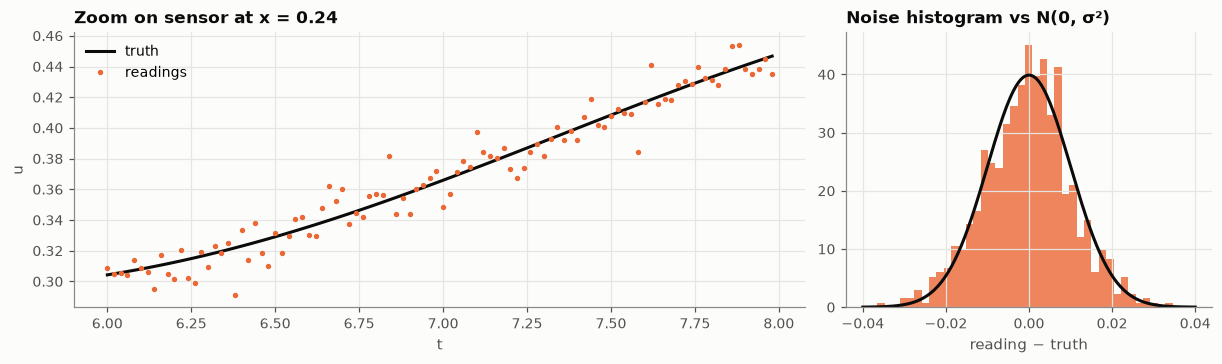

within ±1σ: 68%   within ±2σ: 94%
SNR = signal std / noise std = 0.221 / 0.01 = 22


In [17]:
i = 1
resid = Y[:, i] - U_true[:, sens.idx[i]]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), constrained_layout=True,
                         gridspec_kw={"width_ratios": [2, 1]})
seg = slice(300, 400)
axes[0].plot(t[seg], U_true[seg, sens.idx[i]], color=viz.TRUTH, label="truth")
axes[0].plot(t[seg], Y[seg, i], ".", color=viz.DATA, ms=5, label="readings")
axes[0].set(xlabel="t", ylabel="u", title=f"Zoom on sensor at x = {xs[i]:.2f}")
axes[0].legend()
axes[1].hist(resid, bins=40, color=viz.DATA, alpha=0.8, density=True)
g = np.linspace(-0.04, 0.04, 200)
axes[1].plot(g, np.exp(-g**2 / (2 * 0.01**2)) / (0.01 * np.sqrt(2 * np.pi)), color=viz.INK)
axes[1].set(xlabel="reading − truth", title="Noise histogram vs N(0, σ²)")
plt.show()
signal = U_true[:, sens.idx[i]].std()
print(f"within ±1σ: {np.mean(np.abs(resid) < 0.01):.0%}   within ±2σ: {np.mean(np.abs(resid) < 0.02):.0%}")
print(f"SNR = signal std / noise std = {signal:.3f} / 0.01 = {signal/0.01:.0f}")

## B4. Data only: fill in the gaps by interpolation
Without any physics, the simplest guess between sensors is to **interpolate**. We assume we know
the ends are at 0 (ice baths) and try straight lines (linear) and a smooth curve (cubic spline).

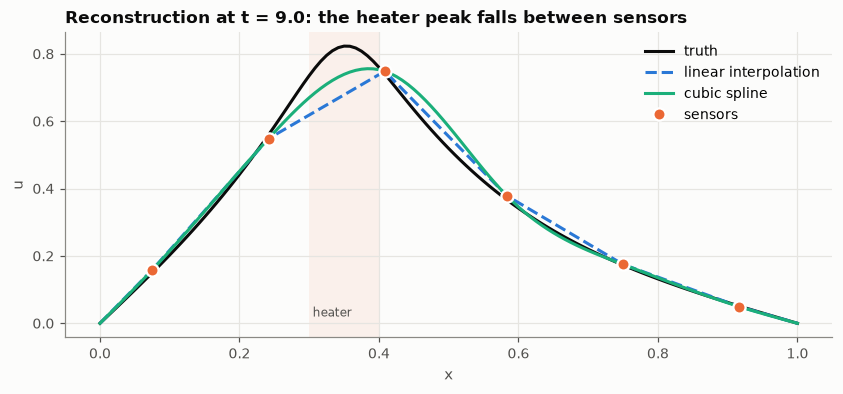

In [18]:
def interp_field(y, xs, x, kind="linear"):
    xp = np.r_[0.0, xs, 1.0]
    yp = np.r_[0.0, y, 0.0]
    return np.interp(x, xp, yp) if kind == "linear" else CubicSpline(xp, yp, bc_type="natural")(x)

k = int(9.0 / real.dt)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(x, U_true[k], color=viz.TRUTH, label="truth")
ax.plot(x, interp_field(Y[k], xs, x, "linear"), color=viz.BLUE, ls="--", label="linear interpolation")
ax.plot(x, interp_field(Y[k], xs, x, "cubic"), color=viz.AQUA, label="cubic spline")
ax.plot(xs, Y[k], "o", color=viz.DATA, ms=8, mec="white", mew=1.5, label="sensors", zorder=5)
ax.axvspan(0.3, 0.4, color=viz.ORANGE, alpha=0.08, lw=0)
ax.text(0.305, 0.02, "heater", color=viz.INK2, fontsize=8)
ax.set(xlabel="x", ylabel="u", title=f"Reconstruction at t = {t[k]:.1f}: the heater peak falls between sensors")
ax.legend()
plt.show()

Interpolation misses the peak: no sensor sits on it, and interpolation doesn't know a heater
exists.

More sensors make interpolation better. Does the error keep falling forever, and what does
noise do?

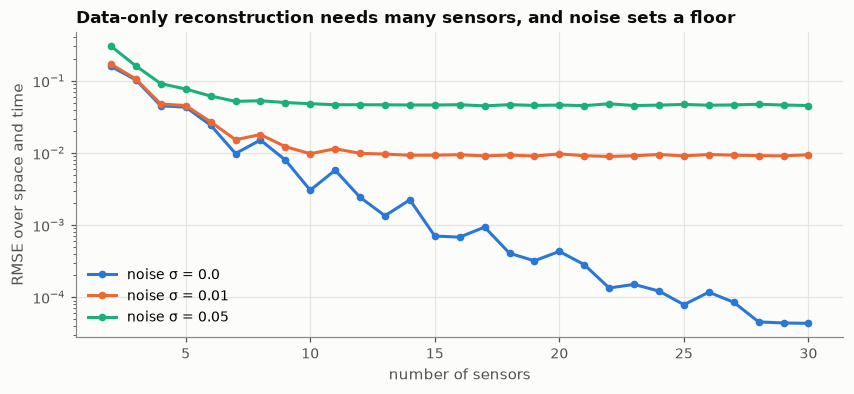

In [19]:
ms = np.arange(2, 31)
fig, ax = plt.subplots(figsize=(9, 3.6))
for j, sd in enumerate([0.0, 0.01, 0.05]):
    err = []
    for m in ms:
        s = PointSensors(evenly_spaced_1d(real.nx, m, margin=0.03), real.nx, sd)
        Ym = s.observe(U_true[::10], rng)
        rec = np.array([interp_field(y, x[s.idx], x, "cubic") for y in Ym])
        err.append(np.sqrt(np.mean((rec - U_true[::10]) ** 2)))
    ax.semilogy(ms, err, "o-", ms=4, color=viz.SERIES[j], label=f"noise σ = {sd}")
ax.set(xlabel="number of sensors", ylabel="RMSE over space and time",
       title="Data-only reconstruction needs many sensors, and noise sets a floor")
ax.legend()
plt.show()

With perfect sensors the error keeps falling. With noise it flattens at roughly $\sigma$:
interpolation passes *through* every noisy reading, so it can never be better than the sensors.
And interpolation can't **forecast**; it says nothing about $t + 1$. Both limits need physics.

---
# Part C · Physics without data: the open-loop twin

## C1. A twin that never looks at its sensors
Now the opposite extreme. Our model has the right equation, but its settings come from a
datasheet: $\alpha = 0.008$ instead of $0.012$, and it assumes the heater runs at a constant
0.6. It **never looks at the data**. This is called running **open loop**.

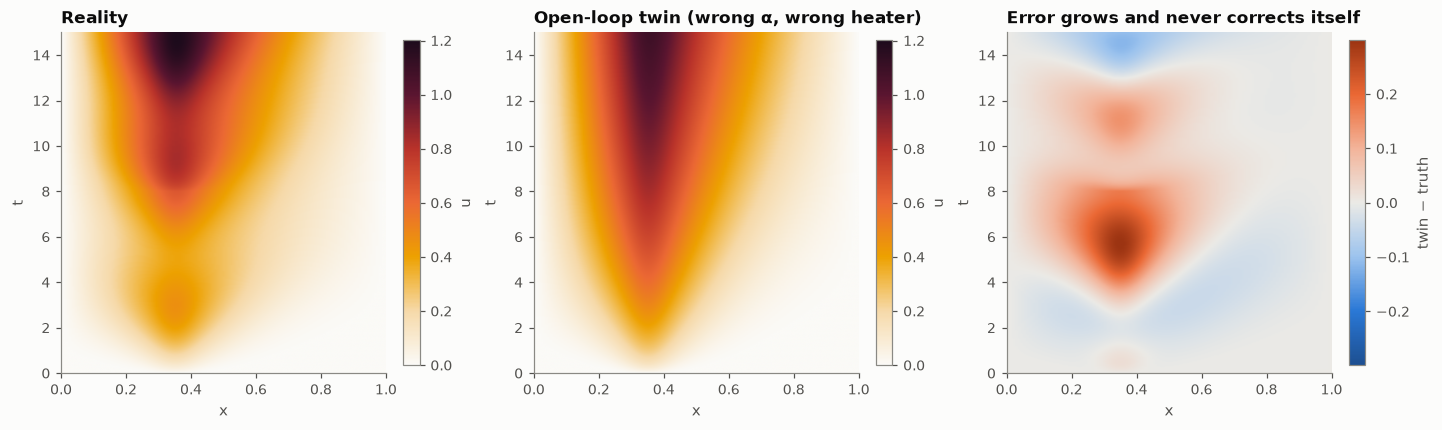

In [20]:
twin = Heat1D(nx=121, alpha=0.008, dt=0.02)
_, U_open = twin.simulate(np.zeros_like(x), 750, source=lambda x, t: 0.6 * heater_shape(x))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), constrained_layout=True)
vmax = max(U_true.max(), U_open.max())
viz.spacetime(axes[0], U_true, x, t, vmin=0, vmax=vmax, label="u")
axes[0].set_title("Reality")
viz.spacetime(axes[1], U_open, x, t, vmin=0, vmax=vmax, label="u")
axes[1].set_title("Open-loop twin (wrong α, wrong heater)")
err = U_open - U_true
lim = np.abs(err).max()
viz.spacetime(axes[2], err, x, t, cmap=viz.DIVERGING, vmin=-lim, vmax=lim, label="twin − truth")
axes[2].set_title("Error grows and never corrects itself")
plt.show()

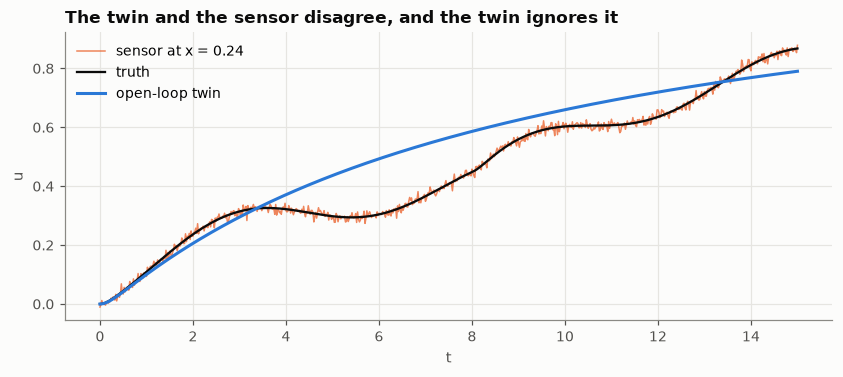

In [21]:
fig, ax = plt.subplots(figsize=(9, 3.4))
i = 1  # the sensor closest to the heater
ax.plot(t, Y[:, i], color=viz.DATA, lw=1, alpha=0.8, label=f"sensor at x = {xs[i]:.2f}")
ax.plot(t, U_true[:, sens.idx[i]], color=viz.TRUTH, lw=1.5, label="truth")
ax.plot(t, U_open[:, sens.idx[i]], color=viz.TWIN, label="open-loop twin")
ax.set(xlabel="t", ylabel="u", title="The twin and the sensor disagree, and the twin ignores it")
ax.legend()
plt.show()

In [22]:
idx = np.arange(0, len(t), 12)
anim = viz.animate_1d(x, [U_true[idx], U_open[idx]], t[idx], labels=["reality", "open-loop twin"],
                      colors=[viz.TRUTH, viz.TWIN], styles=["-", "--"],
                      points=(xs, Y[idx]), title="Reality vs. open-loop twin")
HTML(anim.to_jshtml())

## C2. Which wrong ingredient hurts most?
The twin has two errors: the wrong $\alpha$ and the wrong heater. Fix them one at a time to see
how much each contributes. This **error attribution** tells you what to calibrate first, and it
is exactly what Chapter 2 does with data.

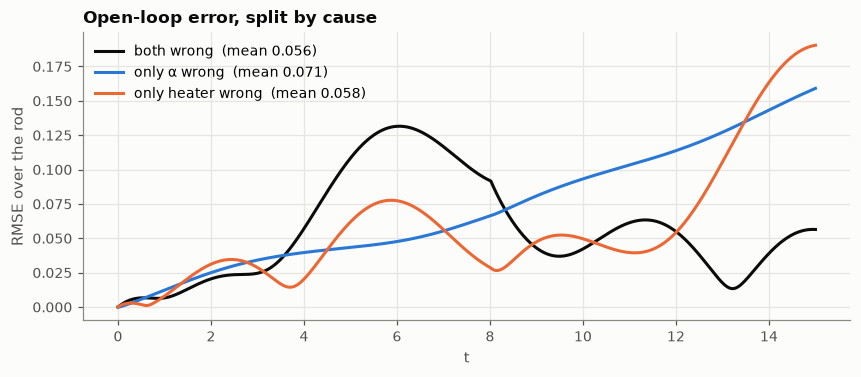

In [23]:
cases = {
    "both wrong":          (0.008, lambda x, t: 0.6 * heater_shape(x)),
    "only α wrong":        (0.008, lambda x, t: true_power(t) * heater_shape(x)),
    "only heater wrong":   (TRUE_ALPHA, lambda x, t: 0.6 * heater_shape(x)),
}
fig, ax = plt.subplots(figsize=(9, 3.4))
for j, (name, (a, src)) in enumerate(cases.items()):
    _, Uc = Heat1D(nx=121, alpha=a, dt=0.02).simulate(np.zeros_like(x), 750, source=src)
    rmse = np.sqrt(np.mean((Uc - U_true) ** 2, axis=1))
    ax.plot(t, rmse, color=[viz.INK, viz.BLUE, viz.ORANGE][j], label=f"{name}  (mean {rmse.mean():.3f})")
ax.set(xlabel="t", ylabel="RMSE over the rod", title="Open-loop error, split by cause")
ax.legend()
plt.show()

Surprise: **"both wrong" has the smallest error.** The two mistakes partly cancel. A too-small
$\alpha$ keeps heat near the heater (too hot), while a heater stuck at 0.6 misses the step up at
$t = 8$ (too cold). Look at how each error behaves:
* a wrong **parameter** ($\alpha$, blue) causes error that **keeps growing**: heat spreads at the
  wrong rate the whole time
* a wrong **input** (heater, orange) causes error that **follows the load**: it rises and falls
  with the oscillation and jumps after the step at $t = 8$

Two lessons for twin builders:
1. **A small error does not prove a correct model.** Compensating errors can make a wrong model
   look right for a while, and then it fails when conditions change. Chapter 2 calls this
   *identifiability*.
2. Fix both kinds of error: parameters with **calibration**, time-varying inputs and states
   with **filtering**.

---
# Summary: the twin gap
| Approach | Strength | Weakness |
|---|---|---|
| **Data only** (interpolation) | agrees with the sensors | blind between sensors, can't beat the noise, can't forecast |
| **Physics only** (open loop) | full field and a forecast | drifts if parameters, inputs or initial state are wrong |
| **Digital twin** = physics **+** data | the best of both | *Chapters 2 to 13* |

**Key ideas**
1. The heat equation is energy bookkeeping, and curvature drives change.
2. Finite differences turn derivatives into neighbour arithmetic; verify the error rate.
3. Explicit schemes have a speed limit ($r \le 1/2$); implicit schemes trade it for a linear solve.
4. Sensors are a matrix $H$ plus noise $R$. That language is used everywhere from here on.
5. Neither data alone nor physics alone is enough.

**Next: Chapter 2** closes the gap in 1D: first **calibration** (find $\alpha$ from data), then
the **Kalman filter** (correct the state and track the heater power live).